# Experiment 01: One output per meter type

Card: [exp01_outputs.md](../../experiments/exp01_outputs.md)


In [12]:
import os
import sys

import matplotlib.pyplot as plt
import mlflow
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
from tqdm import tqdm

sys.path.insert(0, "../../..")  # the ashrae package lives in the homework folder
from ashrae.config import FOLDS, METERS, MODEL_COLORS
from ashrae.data import read_processed, split
from ashrae.features import build_features
from ashrae.metrics import rmsle, rmsle_by_meter
from ashrae.modeling import MLP, MeterMLP, make_loaders, predict
from ashrae.tracking import Experiment

SMOKE = os.environ.get("SMOKE") == "1"
NOTEBOOK = "exp01_outputs"
if SMOKE:
    EXPERIMENT = "ashrae-mlp-outputs-smoke"
    TRAIN = True
    FOLD_NAMES = list(FOLDS)[:2]
    N_TRAIN, N_VAL = 20_000, 5_000
    EPOCHS = 2
    FIGURE = None
else:
    TRAIN = False
    EXPERIMENT = "ashrae-mlp-outputs"
    FOLD_NAMES = list(FOLDS)
    N_TRAIN, N_VAL = 2_000_000, 500_000
    EPOCHS = 10
    FIGURE = "../../figures/exp01_outputs.png"
SESSION = None if TRAIN else "2026-10-12 10:53:33"
NETS = MODELS = ["mlp", "mlp_4out"]
# lgbm_building from baseline exp01, the baseline kept in baseline/baseline_report.md
BASELINE = ("ashrae-baseline-building", "2026-10-11 11:16:15", "lgbm_building")

experiment = Experiment(EXPERIMENT, NOTEBOOK, SESSION)

MLflow: sqlite:////Users/lupaskodmitro/FuckIT/Machine Learning/Deep Learning Homeworks/Homework 1 MLP/mlflow.db, experiment 'ashrae-mlp-outputs', session 2026-10-12 10:53:33


## Training


In [13]:
def scores(y, pred, meter, anomaly):
    """Validation RMSLE on all rows (overall and per meter) and on clean rows."""
    return {
        **rmsle_by_meter(y, pred, meter),
        "val_rmsle_clean": rmsle(y[~anomaly], pred[~anomaly]),
    }


if TRAIN:
    df = read_processed()
    folds = {}
    for fold in tqdm(FOLD_NAMES, desc="fold data", unit="fold"):
        train_df, val_df = split(df, FOLDS[fold], N_TRAIN, N_VAL)
        year_median = train_df.year_built.median()
        X_train, X_val = build_features(train_df, year_median), build_features(
            val_df, year_median
        )
        folds[fold] = {
            "loaders": make_loaders(train_df, val_df, X_train, X_val)[:2],
            "y_val": np.log1p(val_df.meter_reading.to_numpy(dtype="float32")),
            "meter": val_df.meter.to_numpy(),
            "anomaly": val_df.anomaly.to_numpy(),
        }
    del df
    n_features = X_train.shape[1]
    make = {
        "mlp": lambda: MLP(n_features),
        "mlp_4out": lambda: MeterMLP(n_features),
    }
    for fold, d in folds.items():
        train_loader, val_loader = d["loaders"]
        for name in NETS:
            model, run_id = experiment.fit(
                make[name],
                train_loader,
                val_loader,
                run_name=f"{name} | {fold}",
                epochs=EPOCHS,
                tags={"fold": fold, "model": name},
                params={"n_train": N_TRAIN, "n_val": N_VAL},
            )
            s = scores(d["y_val"], predict(model, val_loader), d["meter"], d["anomaly"])
            # Lightning already logged the overall val_rmsle per epoch
            experiment.log_metrics(
                run_id, {k: v for k, v in s.items() if k != "val_rmsle"}
            )

## Results


In [14]:
runs = experiment.runs()
results = runs.rename(
    columns=lambda c: c.removeprefix("metrics.").removeprefix("tags.")
)
results = results[results.model.isin(MODELS)]
print(f"MLflow session {experiment.session}: {len(results)} runs")

table = results.pivot(index="model", columns="fold", values="val_rmsle").loc[
    MODELS, FOLD_NAMES
]
averages = results.groupby("model")[
    ["val_rmsle", "val_rmsle_clean", "train_rmsle"]
].mean()
table["average"] = averages.val_rmsle
table["average, clean rows"] = averages.val_rmsle_clean
table["training"] = averages.train_rmsle  # last epoch
display(table.round(3).rename_axis("RMSLE, all rows unless noted"))

meters = (
    results.groupby("model")[[f"val_rmsle_{name}" for name in METERS.values()]]
    .mean()
    .loc[MODELS]
)
display(
    meters.rename(columns=lambda c: c.removeprefix("val_rmsle_"))
    .round(3)
    .rename_axis("fold average, all rows")
)

MLflow session 2026-10-12 10:53:33: 8 runs


fold,Jan–Mar,Apr–Jun,Jul–Sep,Oct–Dec,average,"average, clean rows",training
"RMSLE, all rows unless noted",,,,,,,
mlp,1.719,1.593,1.497,1.427,1.559,1.380,1.345
mlp_4out,1.698,1.584,1.484,1.419,1.546,1.369,1.331


,electricity,chilledwater,steam,hotwater
"fold average, all rows",,,,
mlp,1.163,1.899,2.121,2.009
mlp_4out,1.158,1.881,2.106,1.972


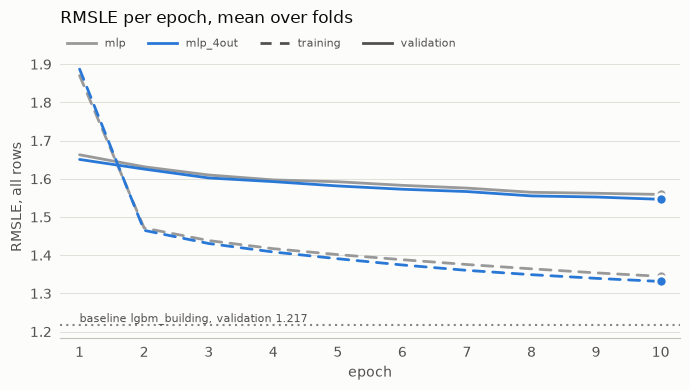

In [15]:
epochs = np.arange(1, EPOCHS + 1)
SPLITS = {"train_rmsle": ("training", (0, (4, 3))), "val_rmsle": ("validation", "-")}
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
curves = {
    (name, key): np.mean(
        [experiment.history(r, key) for r in results[results.model == name].run_id],
        axis=0,
    )
    for name in NETS
    for key in SPLITS
}
baseline_runs = mlflow.search_runs(
    experiment_names=[BASELINE[0]], filter_string=f"tags.session = '{BASELINE[1]}'"
)
baseline = baseline_runs[
    baseline_runs["tags.mlflow.runName"].isin(
        [f"{BASELINE[2]} | {fold}" for fold in FOLD_NAMES]
    )
]["metrics.val_rmsle"].mean()
fig, ax = plt.subplots(figsize=(7, 4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.axhline(baseline, color=MUTED, ls=(0, (1, 2)), lw=1.5)
ax.text(
    1,
    baseline,
    f"baseline {BASELINE[2]}, validation {baseline:.3f}",
    color="#52514e",
    fontsize=8,
    va="bottom",
)
for (name, key), curve in curves.items():
    ax.plot(
        epochs,
        curve,
        color=MODEL_COLORS[name],
        ls=SPLITS[key][1],
        lw=2,
        solid_capstyle="round",
        dash_capstyle="round",
    )
    ax.plot(
        epochs[-1], curve[-1], "o", ms=8, color=MODEL_COLORS[name], mec=SURFACE, mew=2
    )
ax.set(
    xlabel="epoch",
    xticks=epochs,
    xlim=(0.7, epochs[-1] + 0.3),
    ylabel="RMSLE, all rows",
)
ax.set_title("RMSLE per epoch, mean over folds", loc="left", color=INK, pad=24)
ax.grid(axis="y", color=GRID, lw=0.75)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")
ax.tick_params(colors=MUTED, labelcolor="#52514e", length=0, pad=6)
ax.xaxis.label.set_color("#52514e")
ax.yaxis.label.set_color("#52514e")
# Legend in one row under the title: color names the model, line style the split
handles = [Line2D([], [], color=MODEL_COLORS[name], lw=2, label=name) for name in NETS]
handles += [
    Line2D([], [], color="#52514e", ls=style, lw=2, label=label)
    for label, style in SPLITS.values()
]
ax.legend(
    handles=handles,
    ncol=4,
    frameon=False,
    fontsize=8,
    handlelength=2.6,
    labelcolor="#52514e",
    loc="lower left",
    bbox_to_anchor=(0, 1.0),
    borderaxespad=0.2,
)
plt.tight_layout()
if FIGURE:
    fig.savefig(FIGURE, dpi=150, bbox_inches="tight")
    for run_id in results.run_id:
        experiment.client.log_artifact(run_id, FIGURE)